![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 02 | Pipelines and Models

*Project 2 — Machine Learning: From Data to Predictions*

**Alex Russell**  
**Dataset:** IBM Telco Customer Churn

This notebook keeps all learned preprocessing inside scikit-learn pipelines, compares several model families on the same cross-validation folds, tests one simple engineered feature, tunes the strongest candidates, and chooses the classification threshold using training data only.

---
## 0. Setup

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.functions import (
    RANDOM_STATE,
    add_tenure_group,
    build_preprocessor,
    compare_models,
    load_and_split_data,
)

pd.set_option("display.max_columns", 100)

---
## 1. Load and split

In [2]:
X_train, X_test, y_train, y_test = load_and_split_data()

print("Training:", X_train.shape)
print("Test:", X_test.shape)

print("\nTraining churn rate:")
print(y_train.value_counts(normalize=True))

Training: (5634, 19)
Test: (1409, 19)

Training churn rate:
Churn
No     0.734647
Yes    0.265353
Name: proportion, dtype: float64


---
## 2. The preprocessing pipeline

In [3]:
# True numerical measurements
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Everything else is categorical
# SeniorCitizen is 0/1, but it represents a category rather than a measurement
categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

preprocessor = build_preprocessor(
    numeric_features,
    categorical_features
)

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

preprocessor

Numeric features:
['tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_na

---
## 3. First model in the pipeline

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import make_scorer, recall_score

# Same CV folds as notebook 01
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Main metric = recall for customers who churn
recall_scorer = make_scorer(
    recall_score,
    pos_label="Yes"
)

# Baseline again, using exactly the same folds
dummy = DummyClassifier(strategy="most_frequent")

baseline_scores = cross_val_score(
    dummy,
    X_train,
    y_train,
    cv=cv,
    scoring=recall_scorer
)

# First real model:
# preprocessing -> Logistic Regression
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

logistic_scores = cross_val_score(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=recall_scorer
)

print("Baseline recall:")
print("Mean:", baseline_scores.mean())
print("Std:", baseline_scores.std())

print("\nLogistic Regression recall:")
print("Fold scores:", logistic_scores)
print("Mean:", logistic_scores.mean())
print("Std:", logistic_scores.std())

print("\nImprovement over baseline:",
      logistic_scores.mean() - baseline_scores.mean())

Baseline recall:
Mean: 0.0
Std: 0.0

Logistic Regression recall:
Fold scores: [0.53511706 0.50167224 0.53177258 0.62207358 0.52842809]
Mean: 0.5438127090301004
Std: 0.040884834220564895

Improvement over baseline: 0.5438127090301004


---
## 4. Feature engineering test

In [5]:
from sklearn.preprocessing import FunctionTransformer

# The reusable feature function lives in src/functions.py.
feature_engineer = FunctionTransformer(
    add_tenure_group,
    validate=False
)

categorical_features_fe = categorical_features + ["TenureGroup"]

preprocessor_fe = build_preprocessor(
    numeric_features,
    categorical_features_fe
)

logistic_feature_pipeline = Pipeline([
    ("feature_engineering", feature_engineer),
    ("preprocessor", preprocessor_fe),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

feature_scores = cross_val_score(
    logistic_feature_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=recall_scorer
)

print("Original Logistic Regression recall:")
print(logistic_scores.mean())

print("\nWith TenureGroup recall:")
print(feature_scores.mean())

print("\nChange:")
print(feature_scores.mean() - logistic_scores.mean())

Original Logistic Regression recall:
0.5438127090301004

With TenureGroup recall:
0.5364548494983278

Change:
-0.0073578595317725926


Adding TenureGroup slightly reduced cross-validated recall from 0.544 to 0.536. Because the engineered feature did not improve performance, I did not keep it. The original features will be used for model comparison.

---
## 5. Compare models

,Model,Mean Recall,Std Recall
0,Logistic Regression,0.543813,0.040885
1,Decision Tree,0.500334,0.027789
2,Random Forest,0.485619,0.022023
3,Dummy baseline,0.000000,0.000000


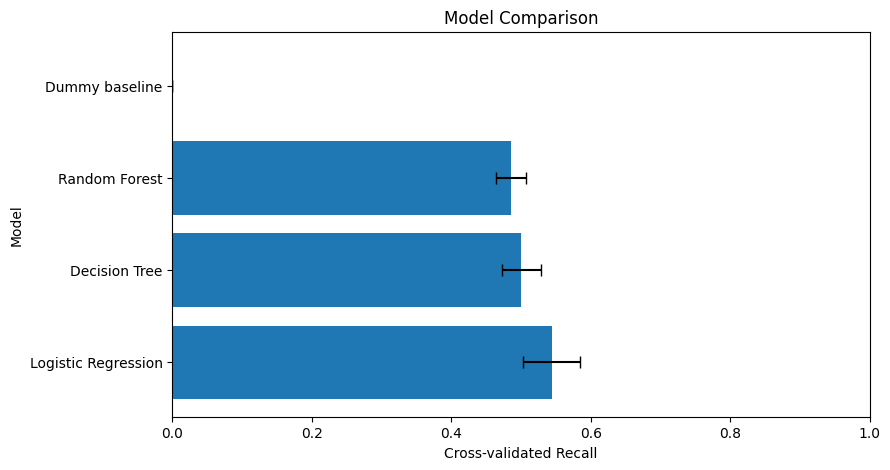

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


models = {

    "Dummy baseline": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=300,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
}


# Compare every model using exactly the same folds
results = compare_models(
    models,
    X_train,
    y_train,
    cv=cv,
    scoring=recall_scorer
)

display(results)


# Plot mean recall and the spread across folds
plt.figure(figsize=(9, 5))

plt.barh(
    results["Model"],
    results["Mean Recall"],
    xerr=results["Std Recall"],
    capsize=4
)

plt.xlabel("Cross-validated Recall")
plt.ylabel("Model")
plt.title("Model Comparison")
plt.xlim(0, 1)

plt.show()

Logistic Regression performed best with a mean recall of 0.544, followed by Decision Tree at 0.500 and Random Forest at 0.486. All three real models clearly beat the dummy baseline of 0. Logistic Regression had slightly more variation across folds, so the gap between it and the Decision Tree is not huge. I will tune the top two models — Logistic Regression and Decision Tree — before choosing the final model.

---
## 6. Tune the strongest candidates

In [7]:
from sklearn.model_selection import GridSearchCV

# -----------------------------
# LOGISTIC REGRESSION
# -----------------------------

logistic_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__class_weight": [None, "balanced"]
}

logistic_search = GridSearchCV(
    estimator=models["Logistic Regression"],
    param_grid=logistic_grid,
    scoring=recall_scorer,
    cv=cv,
    n_jobs=-1
)

logistic_search.fit(X_train, y_train)


# -----------------------------
# DECISION TREE
# -----------------------------

tree_grid = {
    "model__max_depth": [3, 5, 8, None],
    "model__min_samples_leaf": [1, 5, 10, 20],
    "model__class_weight": [None, "balanced"]
}

tree_search = GridSearchCV(
    estimator=models["Decision Tree"],
    param_grid=tree_grid,
    scoring=recall_scorer,
    cv=cv,
    n_jobs=-1
)

tree_search.fit(X_train, y_train)


# -----------------------------
# RESULTS
# -----------------------------

print("LOGISTIC REGRESSION")
print("Best parameters:", logistic_search.best_params_)
print("Best CV recall:", logistic_search.best_score_)

print("\nDECISION TREE")
print("Best parameters:", tree_search.best_params_)
print("Best CV recall:", tree_search.best_score_)

logistic_std = logistic_search.cv_results_["std_test_score"][
    logistic_search.best_index_
]

tree_std = tree_search.cv_results_["std_test_score"][
    tree_search.best_index_
]

print("\nTUNED MODEL SPREAD")
print(f"Logistic Regression: {logistic_search.best_score_:.3f} ± {logistic_std:.3f}")
print(f"Decision Tree:       {tree_search.best_score_:.3f} ± {tree_std:.3f}")
print(
    "Mean difference:",
    round(logistic_search.best_score_ - tree_search.best_score_, 3)
)
print(
    "Improvement from untuned Logistic Regression:",
    round(logistic_search.best_score_ - logistic_scores.mean(), 3)
)

LOGISTIC REGRESSION
Best parameters: {'model__C': 1, 'model__class_weight': 'balanced'}
Best CV recall: 0.8013377926421403

DECISION TREE
Best parameters: {'model__class_weight': 'balanced', 'model__max_depth': 5, 'model__min_samples_leaf': 10}
Best CV recall: 0.7812709030100334

TUNED MODEL SPREAD
Logistic Regression: 0.801 ± 0.038
Decision Tree:       0.781 ± 0.035
Mean difference: 0.02
Improvement from untuned Logistic Regression: 0.258


Tuning improved both models substantially. Logistic Regression reached **0.801 ± 0.038 recall**, while the tuned Decision Tree reached **0.781 ± 0.035**. The difference in their mean recall is only about 0.020, smaller than the normal fold-to-fold variation, so they are effectively close.

The winning Logistic Regression used `C=1` and `class_weight='balanced'`. Because `C=1` is also the default value, most of the improvement from the original 0.544 recall came from deliberately re-weighting the minority churn class. I therefore prefer Logistic Regression: it has the slightly higher mean recall and is the simpler model to explain and deploy.

---
## 7. Choose the classification threshold

Chosen threshold:


,Threshold,Precision,Recall,F1
40,0.5,0.516825,0.801338,0.628377


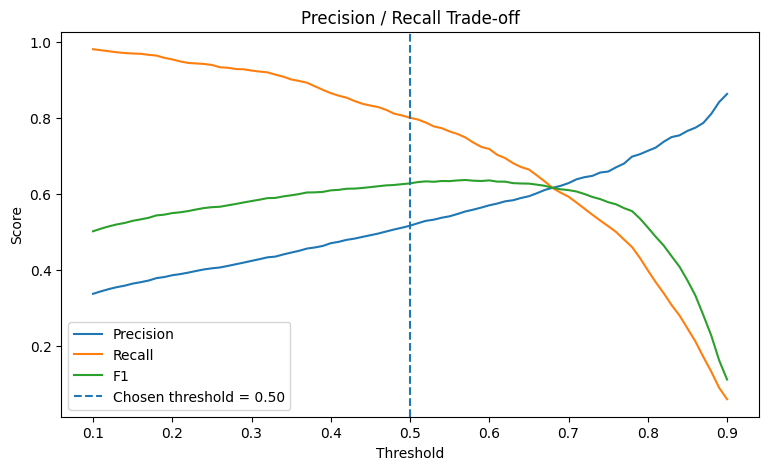

In [8]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score

# Best tuned Logistic Regression pipeline
best_logistic = logistic_search.best_estimator_

# Cross-validated probabilities using TRAINING DATA ONLY
cv_probabilities = cross_val_predict(
    best_logistic,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

# Find the probability column for "Yes"
yes_index = list(best_logistic.named_steps["model"].classes_).index("Yes")
churn_probabilities = cv_probabilities[:, yes_index]


# Try a range of thresholds
threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.01):

    predictions = np.where(
        churn_probabilities >= threshold,
        "Yes",
        "No"
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train,
            predictions,
            pos_label="Yes"
        ),
        "Recall": recall_score(
            y_train,
            predictions,
            pos_label="Yes"
        ),
        "F1": f1_score(
            y_train,
            predictions,
            pos_label="Yes"
        )
    })


threshold_df = pd.DataFrame(threshold_results)


# Keep thresholds that capture at least 80% of churners
acceptable = threshold_df[
    threshold_df["Recall"] >= 0.80
]

# Of those, choose the one with the best precision
best_threshold_row = acceptable.loc[
    acceptable["Precision"].idxmax()
]

best_threshold = best_threshold_row["Threshold"]

print("Chosen threshold:")
display(best_threshold_row.to_frame().T)


# Plot the trade-off
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    label="F1"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Chosen threshold = {best_threshold:.2f}"
)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision / Recall Trade-off")
plt.legend()

plt.show()

I compared classification thresholds using cross-validated probabilities from the training data. The aim was to capture at least 80% of customers who actually churn while keeping precision as high as possible.  
A threshold of 0.50 met this requirement, giving recall of approximately 0.80, precision of approximately 0.52, and an F1 score of approximately 0.63. Because lowering the threshold further would increase recall but create more false positives, I kept the threshold at 0.50.

---
## 8. Final model choice

In [9]:
final_model = logistic_search.best_estimator_
final_threshold = float(round(best_threshold, 2))

print("Final model: Tuned Logistic Regression")
print("Final threshold:", final_threshold)
print("Best CV recall:", logistic_search.best_score_)
print("Best parameters:", logistic_search.best_params_)

Final model: Tuned Logistic Regression
Final threshold: 0.5
Best CV recall: 0.8013377926421403
Best parameters: {'model__C': 1, 'model__class_weight': 'balanced'}


The final model is the tuned Logistic Regression pipeline with `C=1` and `class_weight='balanced'`. It achieved the strongest cross-validated recall, but the Decision Tree was close enough that simplicity matters. Logistic Regression is easier to explain to a non-technical stakeholder, straightforward to deploy, and its behaviour can be inspected through coefficients and permutation importance.

The final threshold is taken directly from the training-only threshold search: **0.50**. The untouched test set has still not been used.